In [2]:
import pandas as pd
import openml
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
%matplotlib inline

In [3]:
import pandas as pd
from sklearn.datasets import fetch_openml

# Fetch dataset 43801 directly from OpenML via ID

# 'as_frame=True' forces scikit-learn to parse the ARFF file directly into a clean Pandas DataFrame
print("Downloading and parsing data...")
oml_data = fetch_openml(data_id=43801, as_frame=True, parser="auto")

# Extract the DataFrame
df = oml_data.frame

len(df)

1061

In [4]:
print(df.head)# extracting the first five rows of the dataset
print(df.shape)# checking the shape of the data
print(df.describe())#statistical analysis of the data
df.to_dict(orient ='records')# converting the dataframe to dictionary 
df.isnull().sum() # checking Missing values

<bound method NDFrame.head of                                        name  selling_price  year seller_type  \
0               'Royal Enfield Classic 350'         175000  2019  Individual   
1                               'Honda Dio'          45000  2017  Individual   
2     'Royal Enfield Classic Gunmetal Grey'         150000  2018  Individual   
3       'Yamaha Fazer FI V 2.0 [2016-2018]'          65000  2015  Individual   
4                   'Yamaha SZ [2013-2014]'          20000  2011  Individual   
...                                     ...            ...   ...         ...   
1056                            'Activa 3g'          17000  2010  Individual   
1057                     'Honda CB twister'          16000  2012  Individual   
1058                   'Bajaj Discover 125'          15000  2013  Individual   
1059                       'Honda CB Shine'          12000  2009  Individual   
1060                     'Bajaj Pulsar 150'          10000  2008  Individual   

         

name                   0
selling_price          0
year                   0
seller_type            0
owner                  0
km_driven              0
ex_showroom_price    435
dtype: int64

In [5]:
# #filling the  missing numners in ex_showroom_price 
df['ex_showroom_price'] = df['ex_showroom_price'].fillna(df['ex_showroom_price'].mean())
df['ex_showroom_price']

0        87958.714058
1        87958.714058
2       148114.000000
3        89643.000000
4        87958.714058
            ...      
1056     52000.000000
1057     51000.000000
1058     57000.000000
1059     58000.000000
1060     75000.000000
Name: ex_showroom_price, Length: 1061, dtype: float64

In [6]:
# finding unique data in the frame
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()
    

name
<StringArray>
[          ''Royal Enfield Classic 350'',
                           ''Honda Dio'',
 ''Royal Enfield Classic Gunmetal Grey'',
   ''Yamaha Fazer FI V 2.0 [2016-2018]'',
               ''Yamaha SZ [2013-2014]'']
Length: 5, dtype: str
279

selling_price
[175000  45000 150000  65000  20000]
130

year
[2019 2017 2018 2015 2011]
28

seller_type
<StringArray>
['Individual', 'Dealer']
Length: 2, dtype: str
2

owner
<StringArray>
[''1st owner'', ''2nd owner'', ''3rd owner'', ''4th owner'']
Length: 4, dtype: str
4

km_driven
[  350  5650 12000 23000 21000]
304

ex_showroom_price
[ 87958.71405751 148114.          89643.          53857.
  87719.        ]
231



In [7]:
#replacing the data frame of year with a new data frame a df['age'] and deleting year columns
df['age'] = 2026 - df['year']
df.drop(columns= ['year','name'], inplace = True)
df

/tmp/ipykernel_17310/95807191.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns= ['year','name'], inplace = True)


,selling_price,seller_type,owner,km_driven,ex_showroom_price,age
0,175000,Individual,'1st owner',350,87958.714058,7
1,45000,Individual,'1st owner',5650,87958.714058,9
2,150000,Individual,'1st owner',12000,148114.000000,8
3,65000,Individual,'1st owner',23000,89643.000000,11
4,20000,Individual,'2nd owner',21000,87958.714058,15
...,...,...,...,...,...,...
1056,17000,Individual,'1st owner',500000,52000.000000,16
1057,16000,Individual,'1st owner',33000,51000.000000,14
1058,15000,Individual,'2nd owner',35000,57000.000000,13
1059,12000,Individual,'1st owner',53000,58000.000000,17


<Axes: xlabel='selling_price', ylabel='Count'>

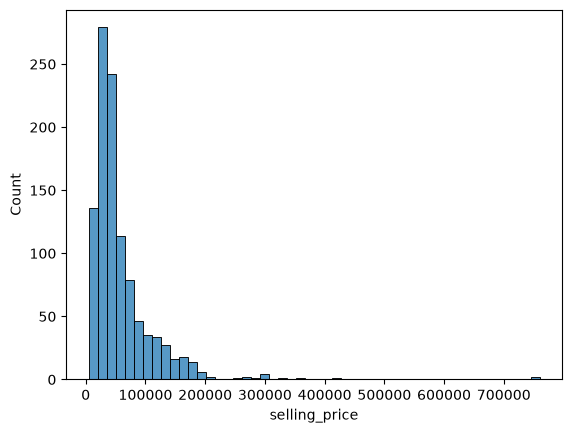

In [8]:
# distributon of the selling  price 
sns.histplot(df.selling_price, bins = 50)

<Axes: xlabel='selling_price', ylabel='Count'>

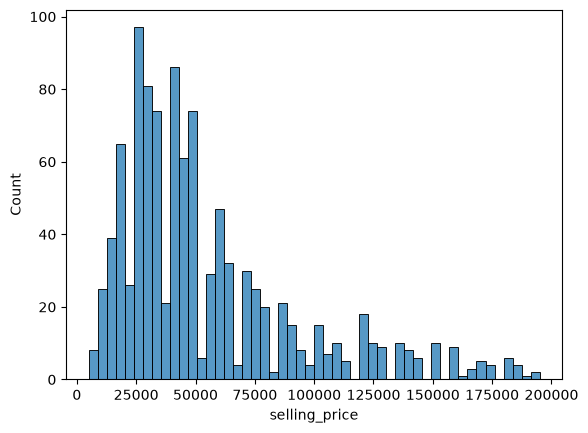

In [9]:
# prices less than $200,000
sns.histplot(df.selling_price[df.selling_price < 200000], bins = 50)

<Axes: xlabel='selling_price', ylabel='Count'>

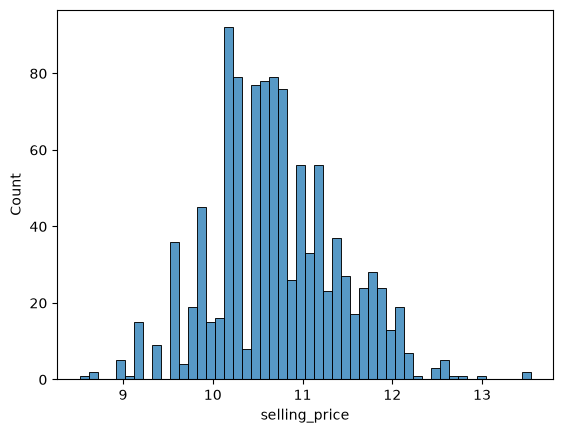

In [10]:
#normalizing the distribution using np.log
selling_price= np.log1p(df.selling_price)
sns.histplot(selling_price, bins= 50)

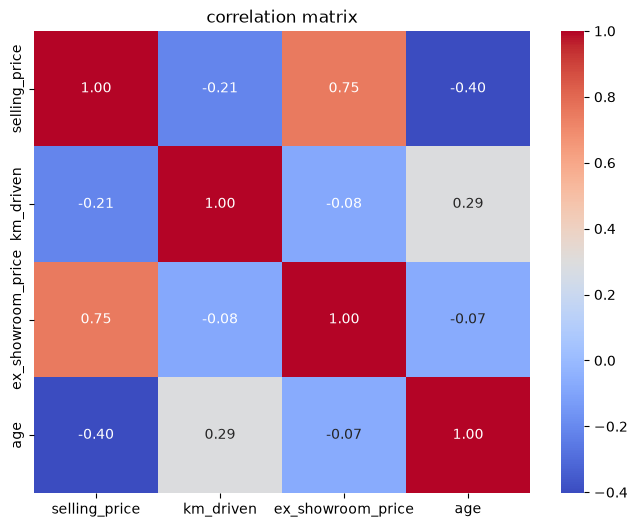

In [11]:
# checkig correlation between all numerical values 

plt.figure (figsize=(8,6))
sns.heatmap(df.corr(numeric_only =True),annot = True, cmap ='coolwarm' , fmt ='.2f')
plt.title('correlation matrix')
plt.show()
          

In [12]:
from sklearn.model_selection import train_test_split 
df_full_train, df_test = train_test_split(df, test_size =0.2, random_state = 11)
df_train ,df_val = train_test_split(df_full_train, test_size =0.25, random_state = 11)

In [13]:
df_train =df_train.reset_index(drop = True)
df_val =df_val.reset_index(drop =True)
df_test = df_test.reset_index(drop = True)

In [14]:
y_train = df_train['selling_price']
y_val = df_val['selling_price']
y_test = df_test['selling_price']



# deleting target variable from being trained
del df_train['selling_price']
del df_val['selling_price']
del df_test['selling_price']

In [15]:
len(y_train)

636

In [16]:
df.dtypes

selling_price          int64
seller_type              str
owner                    str
km_driven              int64
ex_showroom_price    float64
age                    int64
dtype: object

In [17]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import roc_auc_score
from sklearn.tree import export_text
from sklearn.metrics import root_mean_squared_error, r2_score



categorical = ['seller_type','owner']
numerical = ['km_driven','ex_showroom_price','age']

# 1. Prepare your training and validation dictionaries
train_dicts = df_train[categorical + numerical].to_dict(orient='records')
val_dicts = df_val[categorical + numerical].to_dict(orient='records')

# 2. Initialize the Vectorizer
dv = DictVectorizer(sparse=False)

# 3. FIT and TRANSFORM the training data (learns the vocabulary)
X_train = dv.fit_transform(train_dicts)

# 4. TRANSFORM the validation data (uses the learned vocabulary)
X_val = dv.transform(val_dicts)

# DECISION TREE  MODEL
model = DecisionTreeRegressor(max_depth =5, random_state = 42)
model.fit(X_train,y_train)
y_pred = model.predict(X_val)
rmse = root_mean_squared_error(y_val,y_pred)
r2 = r2_score(y_val, y_pred)
r2


0.46904968372287503

In [18]:
#Tuning decison tree 
for depth in [3,4,5,6,7,8]:
    for min_leaves in [2,4,6,8,10,12]:
        model = DecisionTreeRegressor(max_depth =depth, min_samples_leaf = min_leaves,  random_state = 42)
        model.fit(X_train,y_train)
        y_pred = model.predict(X_val)
        rmse = root_mean_squared_error(y_val,y_pred)
        r2 = r2_score(y_val, y_pred)
        print(depth,r2)

3 0.335535052050432
3 0.37767742573099217
3 0.3772686568134368
3 0.37694418442058064
3 0.37748552547884584
3 0.35631705378584755
4 0.4391955978988974
4 0.4746645441804507
4 0.47468384536963637
4 0.471853250924794
4 0.47237779286042925
4 0.42894262733246025
5 0.5112660485819749
5 0.47073293576859376
5 0.5250017402208956
5 0.5226449446554724
5 0.5250605109038651
5 0.46089713475563765
6 0.47651917149467793
6 0.4862404626175145
6 0.5531554892172269
6 0.5507986936518038
6 0.552986800683398
6 0.4477108050202856
7 0.4723046139183732
7 0.48983067639110534
7 0.5496293286265237
7 0.5432279092006007
7 0.5394392536846239
7 0.4438519993978317
8 0.4533346718814647
8 0.5195011459911958
8 0.5647726827960323
8 0.5365751256994449
8 0.5308719191372759
8 0.4380509766818461


In [19]:
# LINEAR REGRESSION MODEL
from sklearn.linear_model import LinearRegression,Ridge,Lasso
Linear_Model = LinearRegression()
Linear_Model.fit(X_train,y_train)
y_pred = Linear_Model.predict(X_val)
r2_linearReg = r2_score(y_val,y_pred)
r2_linearReg

0.29460876911920997

In [20]:
# Using ridge regression

for alpha in [0.1, 1.0, 10.0, 100.0]:
    ridge = Ridge(alpha=alpha, random_state=42)
    ridge.fit(X_train, y_train)
    y_pred = ridge.predict(X_val)
    r2_ridge = r2_score(y_val,y_pred)
    print(r2_ridge)

0.294664025679364
0.2951094936252664
0.29725406088669015
0.3010674824192545


In [21]:
#Using Lassor regression
for alpha in [0.001, 0.01, 0.1, 1.0]:
    for max_iter in [1000,2000,3000,4000]:
        lasso = Lasso(alpha=alpha, random_state=42, max_iter=max_iter)
        lasso.fit(X_train, y_train)
        y_pred = lasso.predict(X_val)
        r2_lasso = r2_score(y_val,y_pred)
        print(r2_lasso)

0.29460527814592485
0.29460527814592485
0.29460527814592485
0.29460527814592485
0.29460683758049133
0.29460683758049133
0.29460683758049133
0.29460683758049133
0.2946415532572838
0.2946415532572838
0.2946415532572838
0.2946415532572838
0.2947759664735221
0.2947759664735221
0.2947759664735221
0.2947759664735221


In [22]:
# RANDOM fOREST
from sklearn.ensemble import RandomForestRegressor

random_model = RandomForestRegressor(n_estimators = 100 , max_depth= 10 , random_state = 42)
random_model.fit(X_train,y_train)
y_pred = random_model.predict(X_val)
r2_randomForest = r2_score(y_val, y_pred)
print(root_mean_squared_error(y_val, y_pred))

24113.86132328983


In [23]:
#tuning randomn forest parameters
for n_estimator in range(100,1000,100):
    for max_depth in [10,15,20]:
        for t in [1,3,5,10,50]:
            random_model = RandomForestRegressor(n_estimators = n_estimator , max_depth= max_depth ,min_samples_leaf = t,  random_state = 42)
            random_model.fit(X_train,y_train)
            y_pred = random_model.predict(X_val)
            r2_randomForest = r2_score(y_val, y_pred)
            rmse_reg = root_mean_squared_error(y_val, y_pred)
            print(t, rmse_reg)
        

1 24113.86132328983
3 24481.483886688948
5 24797.357129137963
10 27322.382797078997
50 32932.97924679758
1 24736.6953744204
3 24653.6109825273
5 24838.244415442798
10 27323.411120056804
50 32932.97924679758
1 24787.363220375428
3 24658.27861185541
5 24838.244415442798
10 27323.411120056804
50 32932.97924679758
1 24339.454014388753
3 24556.379696598884
5 24750.484423289538
10 27168.422172658353
50 32313.532658068892
1 25017.853823194357
3 24712.755571877948
5 24795.035614395063
10 27169.44395840752
50 32313.532658068892
1 25064.81844982952
3 24714.21690611924
5 24795.285502883948
10 27169.44395840752
50 32313.532658068892
1 24263.92836369744
3 24568.762857080135
5 24748.771263492228
10 27136.831002481496
50 32407.218736288516
1 25035.916207305767
3 24693.927537548167
5 24798.79196107892
10 27138.00053703704
50 32407.218736288516
1 25064.13055928145
3 24694.258280870992
5 24798.9030075072
10 27138.00053703704
50 32407.218736288516
1 24193.17568043511
3 24603.416734242706
5 24772.35692508

In [24]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Initialize the model
# learning_rate scales the contribution of each tree
gb_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)

# 2. Train the model
gb_model.fit(X_train, y_train)

# 3. Predict and evaluate
gb_predictions = gb_model.predict(X_val)
print(f"Gradient Boosting RMSE: {root_mean_squared_error(y_val, gb_predictions):.2f}")

Gradient Boosting RMSE: 25974.39


In [ ]:
import xgboost as xgb
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [ ]:
xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'reg:squarederror',
    'nthread': 8,

    'seed': 1,
    'verbosity': 1,
}

model_xgb = xgb.train(xgb_params, dtrain, num_boost_round=10)
y_pred = model_xgb.predict(dval)
rmse = root_mean_squared_error(y_val, y_pred)
rmse